# Exercise 10: warm-ups

The three small tasks from `exercise10_KerasSimpleTrump.ipynb` (Block F). The real trump network is trained with
`python -m jass.train.trump.train_nn`, see the last cell.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras

tf.keras.utils.set_random_seed(0)

## 1. Two colours: mean squared error vs. cross-entropy

Input: the share of cards of two colours; label 1 if colour 1 has more cards. The same network is trained twice,
once with `mse` (as in the notebook) and once with `binary_crossentropy`, the loss that matches a sigmoid output.
The notebook's 2-2 ReLU network stays at chance (49%) with this seed and plain SGD, so it shows nothing about the
loss; one hidden layer of 8 units learns, and cross-entropy gets there faster.

mse                  validation accuracy 0.951


binary_crossentropy  validation accuracy 0.997


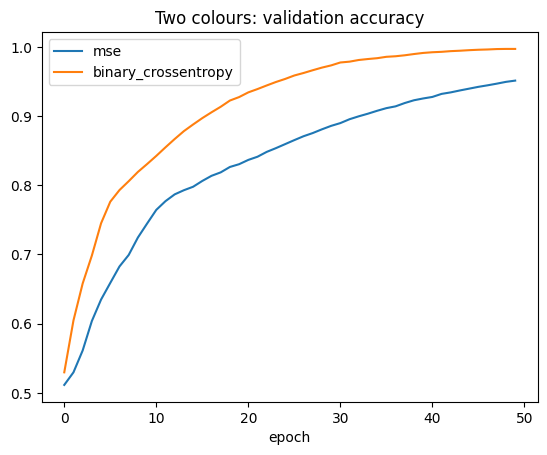

In [2]:
def two_colour_data(n, seed):
    x = np.random.default_rng(seed).random((n, 2)).astype(np.float32)
    return x, (x[:, 1] > x[:, 0]).astype(np.float32)

x_train, y_train = two_colour_data(10000, 1)
x_val, y_val = two_colour_data(5000, 2)

def two_colour_network():
    return keras.Sequential([keras.Input(shape=(2,)),
                             keras.layers.Dense(8, activation='relu'),
                             keras.layers.Dense(1, activation='sigmoid')])

histories = {}
for loss in ['mse', 'binary_crossentropy']:
    tf.keras.utils.set_random_seed(0)
    model = two_colour_network()
    model.compile(loss=loss, optimizer='sgd', metrics=['accuracy'])
    histories[loss] = model.fit(x_train, y_train, validation_data=(x_val, y_val), epochs=50, batch_size=100,
                                verbose=0).history
    print('{:<20} validation accuracy {:.3f}'.format(loss, histories[loss]['val_accuracy'][-1]))

for loss, history in histories.items():
    plt.plot(history['val_accuracy'], label=loss)
plt.title('Two colours: validation accuracy')
plt.xlabel('epoch')
plt.legend()
plt.show()

## 2. Four colours: softmax and categorical cross-entropy

Four inputs, the label is the index of the largest. The labels are one-hot encoded with `to_categorical`, the
output layer is a softmax over four units and the loss is `categorical_crossentropy`.

validation accuracy 0.968


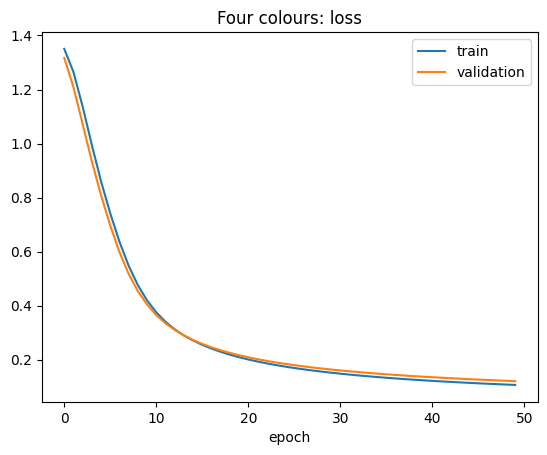

In [3]:
x4 = np.random.default_rng(3).random((5000, 4)).astype(np.float32)
y4 = keras.utils.to_categorical(np.argmax(x4, axis=1), num_classes=4)

tf.keras.utils.set_random_seed(0)
model4 = keras.Sequential([keras.Input(shape=(4,)),
                           keras.layers.Dense(16, activation='relu'),
                           keras.layers.Dense(16, activation='relu'),
                           keras.layers.Dense(4, activation='softmax')])
model4.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
history4 = model4.fit(x4, y4, validation_split=0.25, epochs=50, batch_size=100, verbose=0).history
print('validation accuracy {:.3f}'.format(history4['val_accuracy'][-1]))

plt.plot(history4['loss'], label='train')
plt.plot(history4['val_loss'], label='validation')
plt.title('Four colours: loss')
plt.xlabel('epoch')
plt.legend()
plt.show()

## 3. Trump from the Swisslos data

This is `jass/train/trump/train_nn.py`: 36 cards, the forehand flag and 16 per-suit features
(`'cards+suit'`), two hidden layers 128/64 with dropout, 7 logits (6 trump modes and push) trained with sparse
categorical cross-entropy from logits. It is scored on the same test split as the Ex 8 models and exported to
numpy for the bot:

```
python -m jass.train.trump.train_nn --csv "../materials/Block E_ Supervised Learning Basics/2018_10_18_trump.csv" --out models/trump_nn.npz
```